# Exoplaneten — logaritmen en twaalf SOM-groepen

## Doel
Eén gerichte vergelijking met de bestaande indeling: dezelfde 5.481 planeten, tien eigenschappen, rijvolgorde, startgewichten en SOM-instellingen. De enige verandering is **eerst log10, daarna min-maxschaling**. De oorspronkelijke analyse en modelbestanden blijven bewaard.

Een logaritme maakt van vermenigvuldigen optellen: 1 → 10 geeft dezelfde stap als 10 → 100. Dit werkt hier omdat alle tien gebruikte eigenschappen al strikt positief zijn. Negatieve logaritmen zijn toegestaan; er wordt niets opgeteld of afgeknipt.

**Twaalf groepen blijven vooraf ingesteld.** Hun nummers zijn plaatsnummers in deze nieuwe kaart: de oude groep 4 is niet dezelfde groep als de nieuwe groep 4.

## Uitvoeren
Pak het hele pakket uit en open dit notebook in `modern_som`. Installeer zo nodig `pip install -r requirements.txt`. Het notebook gebruikt de bewaarde NASA-momentopname. `analysis.py` bevat de bestaande datafilters en online-SOM; `log_som.py` bevat dit experiment. Er wordt geen nieuwe download gedaan.

Instellingen: 12×1 knopen, 1.600 volledige doorgangen, alpha 0,05, sigma 4, seed 42. Geen robuuste schaling, nieuwe kenmerken of herweging. De vier stereigenschappen en onderlinge afhankelijkheden blijven dus bestaan.

In [1]:
from pathlib import Path
import json,contextlib,io
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
import log_som
from analysis import ROOT,FEATURES,LABELS
with contextlib.redirect_stdout(io.StringIO()):
    result=log_som.run()
assert result['n']==5481 and result['occupied_groups']==12
display(Markdown(f"**{result['n']:,} planeten; {result['occupied_groups']} bezette groepen.**  \nBronmomentopname (UTC): {result['source_retrieved_utc']}."))

**5,481 planeten; 12 bezette groepen.**  
Bronmomentopname (UTC): 2026-10-17T23:36:52.955890+00:00.

## Hoe verandert de weging?
Onderstaande vergelijking gebruikt dezelfde aarde en Neptunus als eerder. Getoond wordt hun absolute verschil na schaling. Dit is een verschil op de ingevoerde schaal, geen percentage van een fysieke eigenschap en geen bewijs van belang. De SOM telt de **kwadraten** van zulke verschillen op.

In [2]:
solar=log_som.solar_system()
old=np.load(ROOT/'results/som_model.npz');new=np.load(ROOT/'results_log/som_model_log.npz')
v=solar.loc[['Aarde','Neptunus'],FEATURES].values
linear=(v-old['minimum'])/(old['maximum']-old['minimum'])
logged=(np.log10(v)-new['log_minimum'])/(new['log_maximum']-new['log_minimum'])
display(pd.DataFrame({'Eigenschap':LABELS,'Verschil lineaire schaal':abs(linear[1]-linear[0]),'Verschil log-schaal':abs(logged[1]-logged[0])}).round(5))

,Eigenschap,Verschil lineaire schaal,Verschil log-schaal
0,Massa (aarde),0.00172,0.22838
1,Straal (aarde),0.11704,0.32198
2,Dichtheid (g/cm³),0.00194,0.10030
3,Instraling (aarde),0.00002,0.34204
4,Evenwichtstemp. (K),0.05843,0.33536
5,Omlooptijd (dagen),0.34962,0.37657
6,Stermassa (zon),0.00000,0.00000
7,Sterstraal (zon),0.00000,0.00000
8,Stertemperatuur (K),0.00000,0.00000
9,Sterlichtkracht (zon),0.00000,0.00000


## De twaalf nieuwe groepen
De kleuren onderaan tonen de mediane percentielrang van iedere fysieke eigenschap binnen de gebruikte populatie. De training zelf gebruikt log10 plus min-max. De exacte medianen staan in de tabel eronder.

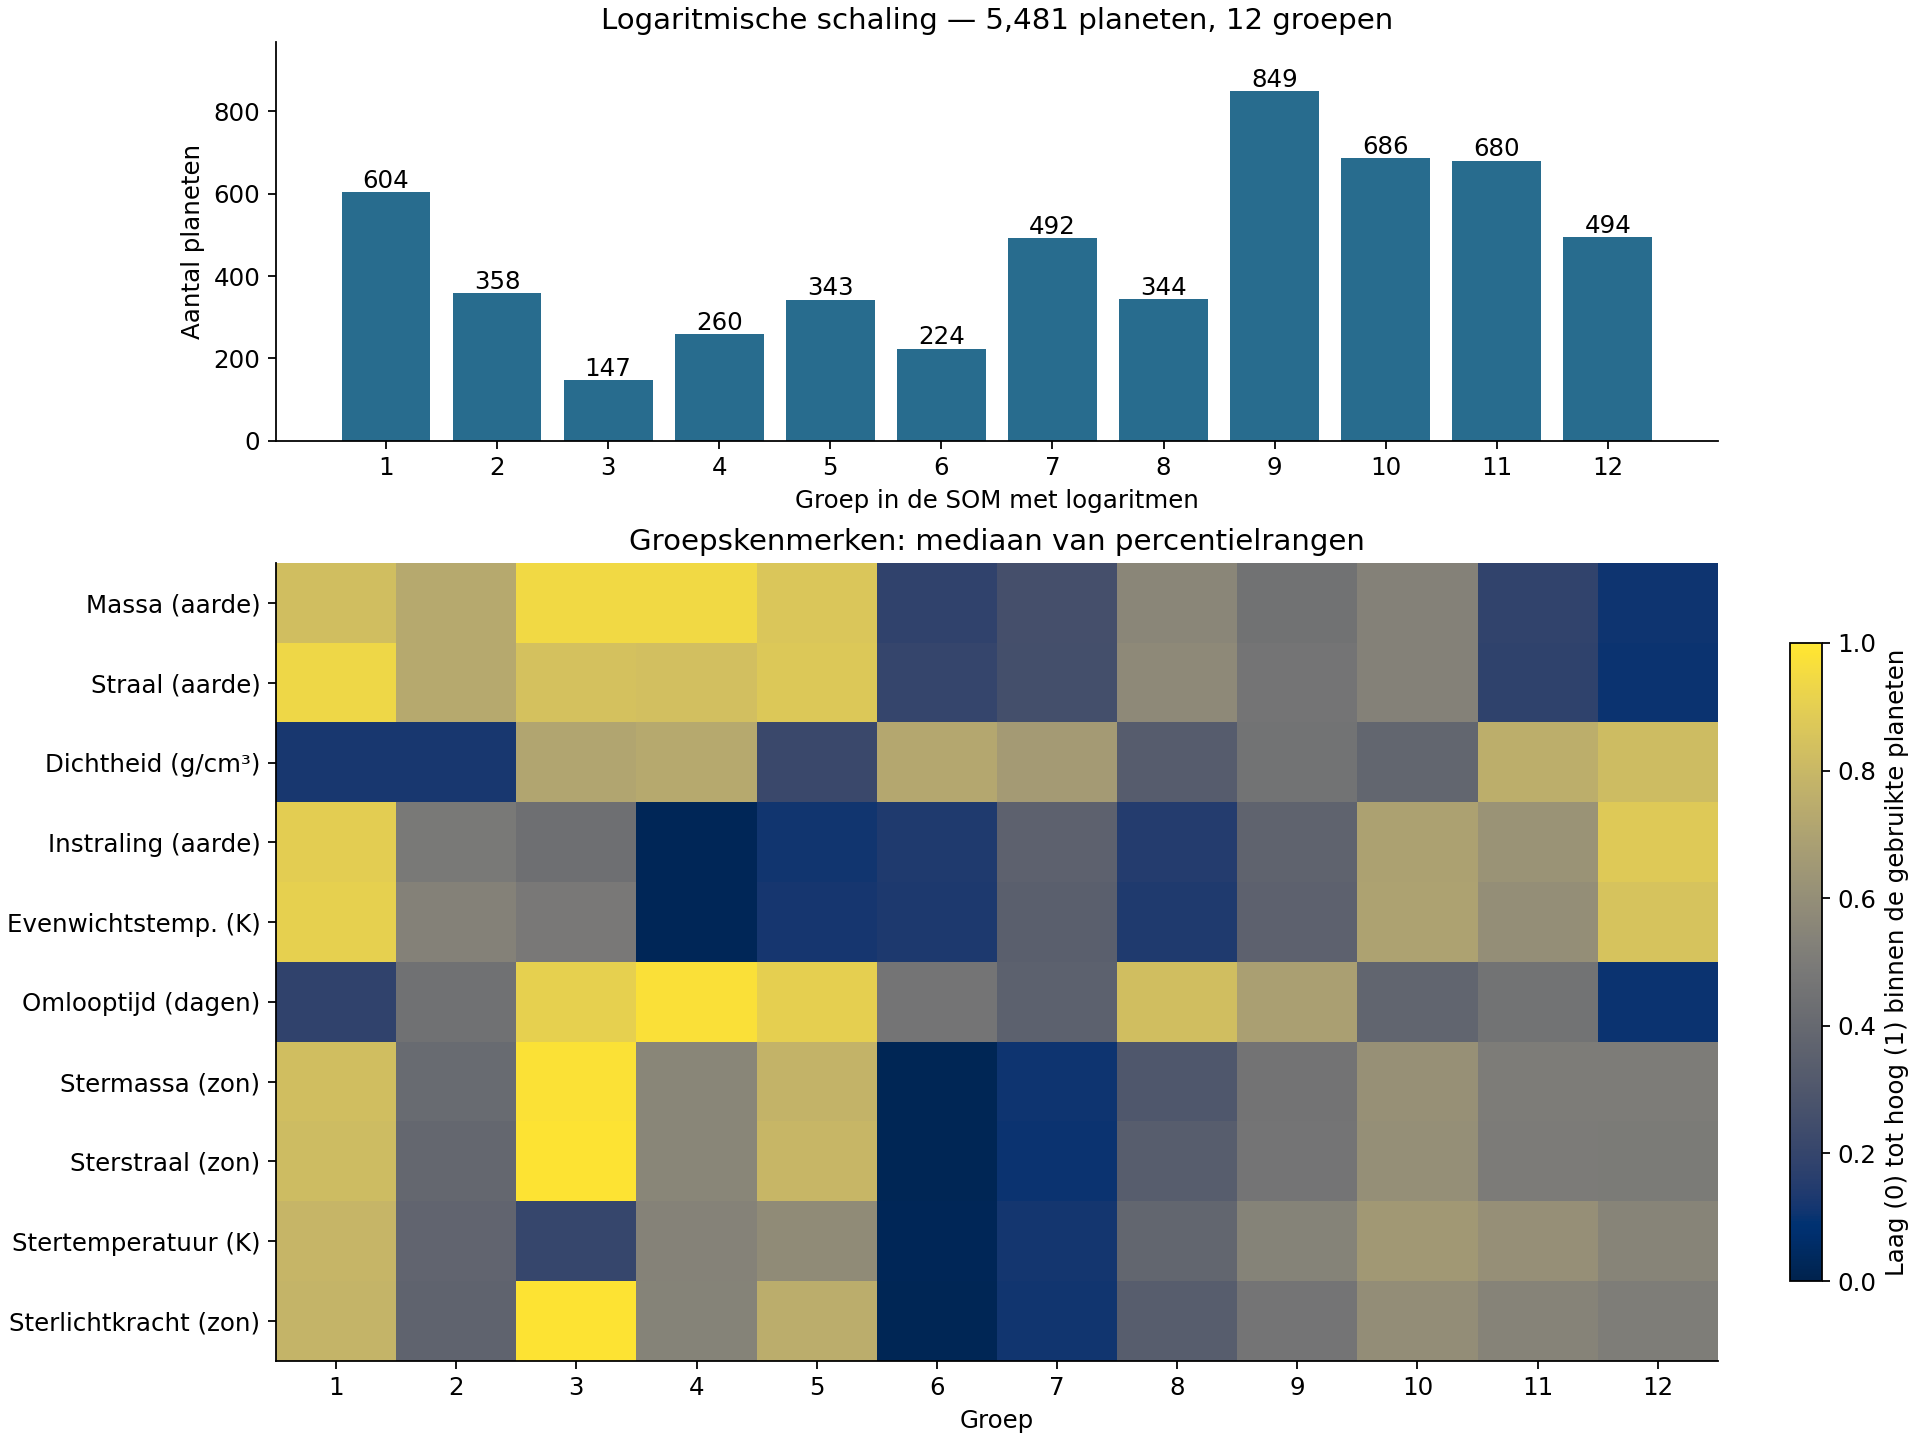

In [3]:
display(Image(filename=str(ROOT/'results_log/som_log_overzicht.png')))

In [4]:
profiles=pd.read_csv(ROOT/'results_log/groepsprofielen_log.csv').rename(columns=dict(zip(FEATURES,LABELS)))
display(profiles.round(3))

,SOM_groep,aantal,Massa (aarde),Straal (aarde),Dichtheid (g/cm³),Instraling (aarde),Evenwichtstemp. (K),Omlooptijd (dagen),Stermassa (zon),Sterstraal (zon),Stertemperatuur (K),Sterlichtkracht (zon)
0,1,604,322.279,14.006,0.610,908.381,1536.500,3.538,1.186,1.400,5976.00,2.365
1,2,358,95.349,10.362,0.610,66.931,797.000,8.743,0.910,0.880,5290.00,0.548
2,3,147,1589.150,12.900,4.070,48.980,747.220,484.170,1.700,11.020,4775.00,58.410
3,4,260,1644.766,12.800,4.300,0.038,127.045,3790.500,0.990,1.019,5622.00,1.022
4,5,343,476.743,13.300,1.110,1.747,325.350,442.190,1.130,1.340,5683.00,2.130
5,6,224,3.180,1.628,4.181,3.065,351.915,9.378,0.290,0.302,3342.00,0.011
6,7,492,4.270,1.842,3.600,28.726,596.500,6.193,0.609,0.580,4109.00,0.099
7,8,344,10.545,3.235,1.735,3.730,355.500,92.168,0.842,0.837,5307.50,0.481
8,9,849,7.510,2.630,2.280,30.968,611.000,24.400,0.939,0.931,5623.00,0.765
9,10,686,9.470,2.936,1.980,209.306,1003.555,6.785,1.020,1.060,5772.42,1.199


## Ons zonnestelsel op dezelfde nieuwe kaart
De acht planeten worden alleen aan de dichtstbijzijnde knoop toegewezen; ze worden niet meegetraind. We gebruiken dezelfde NASA-factsheetgegevens als eerder. Instraling en evenwichtstemperatuur worden vanuit de baanafstand en de zon berekend, met nul terugkaatsing en volledige warmteverdeling. Dit is geen oppervlaktetemperatuur.

De afstand wordt berekend in de nieuwe log-geschaalde ruimte. Hij kan niet rechtstreeks met de afstand van de oude schaling worden vergeleken. Een toewijzing betekent 'dichtstbijzijnde beschikbare groep'; dat hoeft geen goede overeenkomst te zijn.

In [5]:
solar_result=pd.read_csv(ROOT/'results_log/zonnestelsel_log.csv')
display(solar_result[['planeet','oude_groep','log_groep','tweede_log_groep','afstand_log','tweede_afstand_log']].round(4))

,planeet,oude_groep,log_groep,tweede_log_groep,afstand_log,tweede_afstand_log
0,Mercurius,4,11,12,0.5315,0.5797
1,Venus,4,8,9,0.3962,0.3987
2,Aarde,4,8,9,0.3922,0.4237
3,Mars,4,8,11,0.6187,0.6263
4,Jupiter,9,4,5,0.1546,0.3289
5,Saturnus,7,4,5,0.2897,0.4592
6,Uranus,4,4,8,0.5212,0.6509
7,Neptunus,4,4,8,0.5539,0.7308


## Vergelijking en grenzen
De overeenkomst tussen beide volledige indelingen wordt gemeten met de Adjusted Rand Index (ARI). Hierbij tellen groepsnummers niet mee: 1 betekent dezelfde indeling, rond 0 betekent kansniveau. Dit meet verandering, geen verbetering.

De topografische fout is het aandeel planeten waarvoor de twee best passende knopen geen buren zijn. De kwantisatiefout wordt in een andere ruimte gemeten en is daarom niet rechtstreeks te vergelijken met de oorspronkelijke fout.

In [6]:
previous=json.loads((ROOT/'results/samenvatting.json').read_text())
display(pd.DataFrame({'Kenmerk':['Aantal planeten','Bezette groepen','Kleinste groep','Grootste groep','Topografische fout'],'Lineair':[previous['main']['n'],previous['main']['occupied_nodes'],min(previous['main']['sizes'].values()),max(previous['main']['sizes'].values()),previous['main']['topographic_error']],'Logaritmisch':[result['n'],result['occupied_groups'],min(result['group_sizes'].values()),max(result['group_sizes'].values()),result['topographic_error']]}))
display(Markdown(f"**Overeenkomst oude versus nieuwe indeling: ARI {result['adjusted_rand_vs_linear']:.3f}.** De indeling verandert duidelijk. Dat alleen maakt haar nog niet wetenschappelijk beter."))

,Kenmerk,Lineair,Logaritmisch
0,Aantal planeten,5481.000000,5481.000000
1,Bezette groepen,12.000000,12.000000
2,Kleinste groep,25.000000,147.000000
3,Grootste groep,1153.000000,849.000000
4,Topografische fout,0.271483,0.289363


**Overeenkomst oude versus nieuwe indeling: ARI 0.387.** De indeling verandert duidelijk. Dat alleen maakt haar nog niet wetenschappelijk beter.

## Wat zien we?
- Mercurius komt in groep 11; Venus, aarde en Mars in groep 8; de vier buitenplaneten in groep 4.
- Aarde en Neptunus worden nu van elkaar gescheiden. Dit laat zien dat hun eerdere gezamenlijke plek afhing van de schaling.
- Jupiter past relatief dicht bij zijn nieuwe knoop. Verschillende andere zonnestelselplaneten liggen verder van hun beste knoop. Ze kunnen buiten het typische profiel van een groep liggen, ook al vallen hun losse kenmerken binnen het trainingsbereik.
- Alle twaalf groepen zijn bezet. De spreiding in groepsgroottes verandert; dat is op zichzelf geen bewijs van een betere indeling.
- Geschatte massa’s/stralen, minimum-massa’s, ontdekkingsselectie en overlappende informatie blijven in de data aanwezig. Vier kenmerken beschrijven nog steeds de ster.
- Dit experiment heeft één training met de vaste seed 42. Stabiliteit van de nieuwe indeling is hier nog niet onderzocht.

We hebben hiermee twee bewaarde indelingen. Een logisch vervolg is de kenmerken van deze twaalf log-groepen bestuderen, voordat we iets anders aanpassen.

## Bronnen en bestanden
NASA-bronquery, tijdstip en SHA-256: `data/provenance.json`. De dataset is identiek aan de eerste proef; de uitvoercode controleert namen, rijvolgorde en alle tien fysieke waarden tegen de oude uitvoer.

- [NASA Planetary Fact Sheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/)
- [NASA-rekenregels voor exoplaneten](https://exoplanetarchive.ipac.caltech.edu/docs/pscp_calc.html)
- [NASA over PSCompPars](https://exoplanetarchive.ipac.caltech.edu/docs/pscp_about.html)

Nieuwe resultaten staan in `results_log`, waaronder groepsprofielen, alle planeettoewijzingen, zonnestelseltoewijzingen, een kruistabel oud/nieuw, de modelgewichten en log-schaalgrenzen. De oude bestanden in `results` zijn niet vervangen.
